### 06 - Why σ is hard to train

#### Goal (Point 1): visualize |PINN_SS − V_SS| over a uniform grid of test points.

If the PINN's second derivative estimate is inaccurate in some region of (t, S),
the gradient signal used to update sigma in that region is also inaccurate.

In [ ]:
# Use the one for graph 03
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import importlib
import inverse_pinn_model
import inverse_pinn_training

importlib.reload(inverse_pinn_model)
importlib.reload(inverse_pinn_training)

from inverse_pinn_model import InversePINN
from inverse_pinn_training import black_scholes_residual, compute_losses

device = torch.device("cpu")
dtype = torch.float64

checkpoint_vis = torch.load(
    "european_inverse_visualization_checkpoint.pt",
    weights_only=False
)

t_min = checkpoint_vis["t_min"]
t_max = checkpoint_vis["t_max"]
S_min = checkpoint_vis["S_min"]
S_max = checkpoint_vis["S_max"]
K = checkpoint_vis["K"]
T = checkpoint_vis["T"]
r_true = checkpoint_vis["r_true"]
sigma_true = checkpoint_vis["sigma_true"]
hidden_width = checkpoint_vis["hidden_width"]
hidden_layers = checkpoint_vis["hidden_layers"]

model = InversePINN(
    t_min=t_min, t_max=t_max,
    S_min=S_min, S_max=S_max,
    hidden_width=hidden_width,
    hidden_layers=hidden_layers,
    r_initial=0.10,
    sigma_initial=0.40
).to(device=device, dtype=dtype)

model.load_state_dict(checkpoint_vis["model_state_dict"])
model.eval()

print("Loaded trained inverse PINN.")
print("sigma (trained) =", model.sigma.item())
print("r (trained)=", model.r.item())

Loaded trained inverse PINN.
sigma (trained) = 0.1877531445743151
r (trained)= 0.05052711123659477


In [2]:
N_test = 100
epsilon = 1e-3

t_test_1d = torch.linspace(t_min, t_max - epsilon, N_test, dtype=dtype, device=device)
S_test_1d = torch.linspace(S_min + epsilon, S_max, N_test, dtype=dtype, device=device)

t_mesh, S_mesh = torch.meshgrid(t_test_1d, S_test_1d, indexing="ij")

t_test = t_mesh.reshape(-1,1)
S_test = S_mesh.reshape(-1,1)
print("Number of test points:", t_test.shape[0])

Number of test points: 10000


In [11]:
def black_scholes_residual_with_u_SS(model, t, S):
    t_input = t.clone().detach().requires_grad_(True)
    S_input = S.clone().detach().requires_grad_(True)

    u = model(t_input, S_input)

    u_t = torch.autograd.grad(
        outputs=u, inputs=t_input,
        grad_outputs=torch.ones_like(u),
        create_graph=True, retain_graph=True
    )[0]

    u_S = torch.autograd.grad(
        outputs=u, inputs=S_input,
        grad_outputs=torch.ones_like(u),
        create_graph=True, retain_graph=True
    )[0]

    u_SS = torch.autograd.grad(
        outputs=u_S, inputs=S_input,
        grad_outputs=torch.ones_like(u_S),
        create_graph=True, retain_graph=True
    )[0]

    r_est = model.r
    sigma_est = model.sigma

    residual = (
        u_t
        + 0.5 * sigma_est**2 * S_input**2 * u_SS
        + r_est * S_input * u_S
        - r_est * u
    )

    return residual, u, u_t, u_S, u_SS

In [12]:
residual_pinn, u_pinn, u_t_pinn, u_S_pinn, u_SS_pinn = black_scholes_residual_with_u_SS(
    model, t_test, S_test
)

V_SS_pinn = (K * u_SS_pinn).detach()

print("PINN u_SS range:", u_SS_pinn.min().item(), "to", u_SS_pinn.max().item())

PINN u_SS range: -0.0003265387076237671 to 0.002685958648276529


In [13]:
def black_scholes_gamma(t, S, K, T, r, sigma):
    tau = T - t
    eps = 1e-12
    tau_safe = torch.clamp(tau, min=eps)
    S_safe = torch.clamp(S, min=eps)

    d1 = (
        torch.log(S_safe / K)
        + (r + 0.5 * sigma**2) * tau_safe
    ) / (sigma * torch.sqrt(tau_safe))

    N_prime_d1 = torch.exp(-0.5 * d1**2) / np.sqrt(2.0 * np.pi)
    gamma = N_prime_d1 / (S_safe * sigma * torch.sqrt(tau_safe))
    return gamma

with torch.no_grad():
    V_SS_true = black_scholes_gamma(t_test, S_test, K, T, r_true, sigma_true)

print("True Gamma range:", V_SS_true.min().item(), "to", V_SS_true.max().item())

True Gamma range: 0.0 to 0.43191730464095957


In [14]:
abs_error_SS = torch.abs(V_SS_pinn - V_SS_true)

abs_error_grid = abs_error_SS.reshape(N_test, N_test).cpu().numpy()
t_grid_np = t_mesh.cpu().numpy()
S_grid_np = S_mesh.cpu().numpy()

print("max |PINN_SS - V_SS|  :", abs_error_grid.max())
print("mean |PINN_SS - V_SS| :", abs_error_grid.mean())

max_idx = np.unravel_index(np.argmax(abs_error_grid), abs_error_grid.shape)
print("location of max error -> t =", t_grid_np[max_idx], ", S =", S_grid_np[max_idx])

max |PINN_SS - V_SS|  : 0.3244789587098984
mean |PINN_SS - V_SS| : 0.001483283906248043
location of max error -> t = 0.999 , S = 40.40478787878788


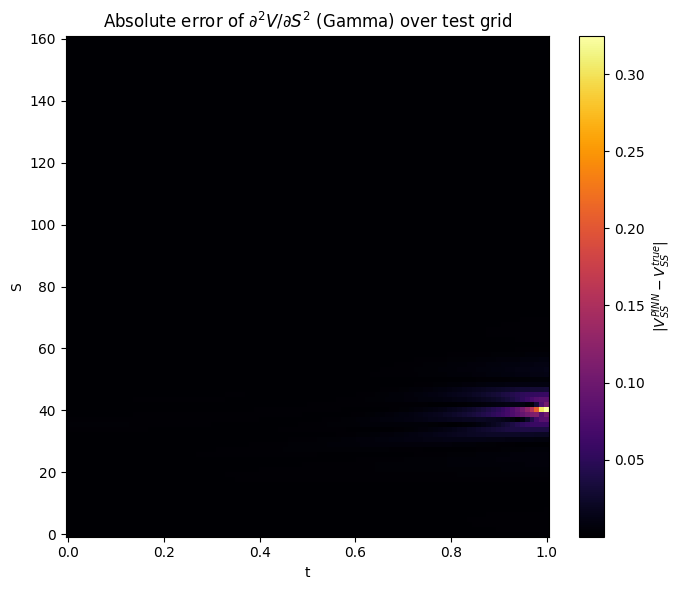

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))

c = ax.pcolormesh(
    t_grid_np, S_grid_np, abs_error_grid,
    shading="auto", cmap="inferno"
)
fig.colorbar(c, ax=ax, label=r"$|V_{SS}^{PINN} - V_{SS}^{true}|$")

ax.set_xlabel("t")
ax.set_ylabel("S")
ax.set_title(r"Absolute error of $\partial^2 V/\partial S^2$ (Gamma) over test grid")

plt.tight_layout()
plt.show()

#### Goal (Point 2): print sigma.item(), sigma.grad.item(), and r.grad.item()

read 10 pre-trained inverse PINN checkpoint --- generate diagnostic points

Conclusion: The raw gradient signal of loss with respect to sigma is much smaller than that with respect to r. 

In [16]:
import pandas as pd
from inverse_pinn_model import InversePINN
from inverse_pinn_training import (
    K, T, t_min, t_max, S_min, S_max,
    N_f, N_terminal, N_boundary, epsilon,
    load_synthetic_data, compute_losses
)

gradient_diagnostics = []

for run in range(1,11):
    checkpoint_path = f"european_inverse_checkpoint_run{run}.pt"
    ckpt = torch.load(checkpoint_path, weights_only=False)

    model_run = InversePINN(
        t_min=ckpt["t_min"], t_max=ckpt["t_max"],
        S_min=ckpt["S_min"], S_max=ckpt["S_max"],
        hidden_width=ckpt["hidden_width"],
        hidden_layers=ckpt["hidden_layers"],
        r_initial=0.10,
        sigma_initial=0.40
    ).to(device=device, dtype=dtype)

    model_run.load_state_dict(ckpt["model_state_dict"])

    t_obs, S_obs, V_obs = load_synthetic_data()
    t_train = t_obs
    S_train = S_obs
    u_train = V_obs / K

    t_f = t_min + epsilon + (t_max - t_min - 2.0 * epsilon) * torch.rand(N_f, 1, dtype=dtype, device=device)
    S_f = S_min + epsilon + (S_max - S_min - 2.0 * epsilon) * torch.rand(N_f, 1, dtype=dtype, device=device)

    t_terminal = torch.full((N_terminal, 1), fill_value=T, dtype=dtype, device=device)
    S_terminal = S_min + (S_max - S_min) * torch.rand(N_terminal, 1, dtype=dtype, device=device)

    t_boundary = t_min + (t_max - t_min) * torch.rand(N_boundary, 1, dtype=dtype, device=device)
    S_boundary_left = torch.full((N_boundary, 1), fill_value=S_min, dtype=dtype, device=device)
    S_boundary_right = torch.full((N_boundary, 1), fill_value=S_max, dtype=dtype, device=device)

    model_run.zero_grad(set_to_none=True)
    losses_run = compute_losses(
        model=model_run,
        t_train=t_train, S_train=S_train, u_train=u_train,
        t_f=t_f, S_f=S_f,
        t_terminal=t_terminal, S_terminal=S_terminal,
        t_boundary=t_boundary,
        S_boundary_left=S_boundary_left,
        S_boundary_right=S_boundary_right
    )
    losses_run["total"].backward()

    run_record = {
        "run": run,
        "sigma_estimate": model_run.sigma.item(),
        "r_estimate": model_run.r.item(),
    }

    for name, param in model_run.named_parameters():
        if param.numel() == 1:
            grad_val = param.grad.item() if param.grad is not None else None
            run_record[f"{name}_raw_value"] = param.item()
            run_record[f"{name}_grad"] = grad_val

    gradient_diagnostics.append(run_record)
    print(f"Run {run} loaded & diagnosed | sigma={run_record['sigma_estimate']:.6f}")

diag_df = pd.DataFrame(gradient_diagnostics)
diag_df.to_csv("sigma_gradient_10run_diagnostics.csv", index=False)
diag_df

Run 1 loaded & diagnosed | sigma=0.189171
Run 2 loaded & diagnosed | sigma=0.181106
Run 3 loaded & diagnosed | sigma=0.182314
Run 4 loaded & diagnosed | sigma=0.188970
Run 5 loaded & diagnosed | sigma=0.166533
Run 6 loaded & diagnosed | sigma=0.171012
Run 7 loaded & diagnosed | sigma=0.182810
Run 8 loaded & diagnosed | sigma=0.170875
Run 9 loaded & diagnosed | sigma=0.167596
Run 10 loaded & diagnosed | sigma=0.185114


,run,sigma_estimate,r_estimate,r_raw_raw_value,r_raw_grad,sigma_raw_raw_value,sigma_raw_grad,model.8.bias_raw_value,model.8.bias_grad
0,1,0.189171,0.050288,-2.964740,-0.000041,-1.569029,1.070649e-06,0.033188,0.007092
1,2,0.181106,0.050420,-2.962045,0.000078,-1.616754,-9.090606e-06,0.040396,-0.012433
2,3,0.182314,0.050555,-2.959318,0.000871,-1.609483,-1.640307e-07,0.042586,-0.159403
3,4,0.188970,0.050489,-2.960645,0.000027,-1.570194,1.470725e-05,0.036124,-0.005294
4,5,0.166533,0.050918,-2.951975,-0.000077,-1.708140,1.695199e-07,0.048448,0.073927
5,6,0.171012,0.050737,-2.955620,-0.000020,-1.679296,-4.343366e-06,0.043726,-0.003915
6,7,0.182810,0.050504,-2.960350,0.000402,-1.606512,1.228659e-04,0.037165,-0.016920
7,8,0.170875,0.050718,-2.956003,0.000044,-1.680167,5.489486e-06,0.051754,0.007589
8,9,0.167596,0.050891,-2.952507,0.000307,-1.701233,3.267057e-05,0.053837,-0.077663
9,10,0.185114,0.050328,-2.963927,0.000883,-1.592798,5.461738e-06,0.039629,-0.202440


In [17]:
grad_cols = [c for c in diag_df.columns if c.endswith("_grad")]
diag_df[grad_cols].abs().agg(["mean", "std"])

,r_raw_grad,sigma_raw_grad,model.8.bias_grad
mean,0.000275,0.000020,0.056668
std,0.000342,0.000038,0.071777


#### Goal (New1): Actual Adam Update Diagnosis。

used european_inverse_adam_update_diagnostic_seed42.pt

After Adam doing optimizer.step(), how much did r_raw and sigma_raw actuall move?


In [28]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

adam_ckpt = torch.load(
    "european_inverse_adam_update_diagnostic_seed42.pt",
    weights_only=False
)

print(adam_ckpt.keys())

dict_keys(['model_state_dict', 'history', 'adam_update_history', 'result', 'seed', 'optimizer', 'learning_rate', 'num_epochs', 'N_f', 'N_terminal', 'N_boundary', 't_min', 't_max', 'S_min', 'S_max', 'K', 'T', 'r_true', 'sigma_true', 'hidden_width', 'hidden_layers'])


In [29]:
adam_history = adam_ckpt["adam_update_history"]

adam_df = pd.DataFrame(adam_history)

print(adam_df.shape)
adam_df.head()

(30000, 7)


,epoch,r_raw_grad,sigma_raw_grad,r_raw_update,sigma_raw_update,r_update,sigma_update
0,1,0.274118,0.001281,-0.001000,-0.001000,-0.000095,-0.000330
1,2,0.272421,-0.006370,-0.001000,0.000597,-0.000095,0.000197
2,3,0.287986,-0.021904,-0.001001,0.000744,-0.000095,0.000245
3,4,0.312622,-0.042946,-0.001004,0.000799,-0.000095,0.000264
4,5,0.335466,-0.065264,-0.001008,0.000841,-0.000096,0.000278


In [30]:
# 总结整个 30000 epochs 的平均 gradient 和实际 update
# |dL/dr_raw| and |dL/dsigma|
adam_summary = adam_df[
    [
        "r_raw_grad",
        "sigma_raw_grad",
        "r_raw_update",
        "sigma_raw_update",
        "r_update",
        "sigma_update",
    ]
].abs().agg(
    ["mean", "std", "median"]
)

adam_summary

,r_raw_grad,sigma_raw_grad,r_raw_update,sigma_raw_update,r_update,sigma_update
mean,0.000747,0.001215,0.000046,0.000067,2.748504e-06,0.000013
std,0.005883,0.007481,0.000059,0.000124,4.332746e-06,0.000034
median,0.000099,0.000016,0.000018,0.000046,9.048046e-07,0.000007


In [31]:
# |gr|/|gsigma| and |dr_raw|/|dsigma_raw|
mean_abs_r_grad = adam_df["r_raw_grad"].abs().mean()
mean_abs_sigma_grad = adam_df["sigma_raw_grad"].abs().mean()

mean_abs_r_update = adam_df["r_raw_update"].abs().mean()
mean_abs_sigma_update = adam_df["sigma_raw_update"].abs().mean()


gradient_ratio = (
    mean_abs_r_grad
    / mean_abs_sigma_grad
)

adam_update_ratio = (
    mean_abs_r_update
    / mean_abs_sigma_update
)


comparison_df = pd.DataFrame(
    {
        "r": [
            mean_abs_r_grad,
            mean_abs_r_update
        ],

        "sigma": [
            mean_abs_sigma_grad,
            mean_abs_sigma_update
        ],

        "r_to_sigma_ratio": [
            gradient_ratio,
            adam_update_ratio
        ]
    },
    index=[
        "Mean absolute raw gradient",
        "Mean absolute Adam update"
    ]
)

comparison_df

,r,sigma,r_to_sigma_ratio
Mean absolute raw gradient,0.000747,0.001215,0.614604
Mean absolute Adam update,0.000046,0.000067,0.680684


In [36]:
adam_df["epoch"] = pd.to_numeric(
    adam_df["epoch"],
    errors="coerce"
)

adam_df["stage"] = pd.cut(
    adam_df["epoch"],
    bins=[0, 5000, 15000, 30000],
    labels=[
        "early (1-5000)",
        "middle (5001-15000)",
        "late (15001-30000)"
    ],
    include_lowest=True
)

stage_summary = (
    adam_df
    .groupby(
        "stage",
        observed=True
    )[
        [
            "r_raw_grad",
            "sigma_raw_grad",
            "r_raw_update",
            "sigma_raw_update"
        ]
    ]
    .agg(
        lambda x: x.abs().mean()
    )
)

stage_summary["gradient_r_to_sigma_ratio"] = (
    stage_summary["r_raw_grad"]
    / stage_summary["sigma_raw_grad"]
)

stage_summary["update_r_to_sigma_ratio"] = (
    stage_summary["r_raw_update"]
    / stage_summary["sigma_raw_update"]
)

stage_summary

,r_raw_grad,sigma_raw_grad,r_raw_update,sigma_raw_update,gradient_r_to_sigma_ratio,update_r_to_sigma_ratio
stage,,,,,,
early (1-5000),0.003556,0.007120,0.000125,0.000171,0.499380,0.731307
middle (5001-15000),0.000189,0.000058,0.000027,0.000031,3.283216,0.888917
late (15001-30000),0.000182,0.000018,0.000032,0.000057,10.098974,0.554423


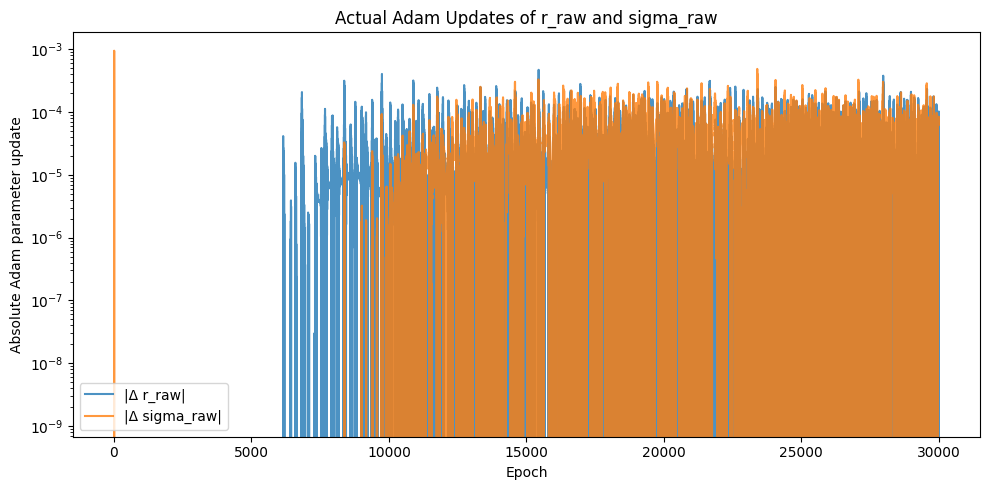

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    adam_df["epoch"],
    adam_df["r_raw_update"],
    label="|Δ r_raw|",
    alpha=0.8
)

plt.plot(
    adam_df["epoch"],
    adam_df["sigma_raw_update"],
    label="|Δ sigma_raw|",
    alpha=0.8
)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("Absolute Adam parameter update")
plt.title(
    "Actual Adam Updates of r_raw and sigma_raw"
)

plt.legend()
plt.tight_layout()
plt.show()

#### conclusion: 虽然 sigma 的 gradient 中后期更小，但 Adam 最终给 sigma 的实际 update 并没有更小，反而还更大。